# TB-INSIGHT — Eksplorasi Dataset dan Referensi Visualisasi Dashboard

Notebook ini mengeksplorasi seluruh dataset analisis-ready pada dua jalur produk di repository:

1. **`product-demo-synthetic`** — data dummy/sintetik untuk demo Surabaya.
2. **`product-ongoing-real-data`** — data resmi untuk panel penelitian nasional.

Tujuannya bukan hanya melihat isi tabel, tetapi memahami:

- variabel apa yang tersedia;
- hubungan antarfile;
- variabel turunan yang dapat dibuat;
- visualisasi yang cocok untuk Overview, Trend, Map, Methods, dan Sources.

Jalankan notebook dari folder root **`TB-INSIGHT`**. Semua path dibuat relatif terhadap root repository, sehingga notebook dapat dipindahkan bersama repository tanpa mengubah path manual.

## Tata kelola data

- Data sintetik hanya digunakan untuk demonstrasi UI/UX, pengujian interaksi, forecast demo, dan simulasi alokasi.
- Data asli memiliki definisi dan keterbatasan yang berbeda. `jumlah_pasien` adalah pasien yang mulai pengobatan TB sensitif obat pada bulan tersebut, bukan otomatis insidensi TB.
- Data outcome 2025 bersifat provisional karena sebagian outcome masih `belum_ada_hasil`.
- Data BPS merupakan data tahunan atau reference-period, bukan observasi bulanan.
- Data iklim berasal dari reanalysis NASA POWER/MERRA-2; data BNPB adalah kovariat sekunder/sensitivity.
- Jangan mencampurkan data atau output sintetik ke pipeline penelitian resmi.

Jika ingin menyimpan grafik sebagai PNG, ubah `SAVE_FIGURES = True` pada sel setup. Secara default grafik hanya ditampilkan di notebook.

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import seaborn as sns
    HAS_SEABORN = True
except ImportError:
    sns = None
    HAS_SEABORN = False

try:
    import geopandas as gpd
    HAS_GEOPANDAS = True
except ImportError:
    gpd = None
    HAS_GEOPANDAS = False

try:
    from IPython.display import display, Markdown
except ImportError:
    def display(obj):
        print(obj)

    def Markdown(text):
        return text

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 160)

def find_repo_root(start=None):
    """Cari folder TB-INSIGHT dari lokasi kernel saat ini."""
    start = Path(start or Path.cwd()).resolve()
    candidates = [start, *start.parents]
    for candidate in candidates:
        if (
            (candidate / "README.md").exists()
            and (candidate / "product-demo-synthetic").is_dir()
            and (candidate / "product-ongoing-real-data").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Folder TB-INSIGHT tidak ditemukan. Jalankan notebook dari root repository "
        "atau ubah fungsi find_repo_root()."
    )

REPO_ROOT = find_repo_root()
DUMMY_ROOT = REPO_ROOT / "product-demo-synthetic"
REAL_ROOT = REPO_ROOT / "product-ongoing-real-data"
FIG_DIR = REPO_ROOT / "notebook_outputs" / "figures"
SAVE_FIGURES = False

if HAS_SEABORN:
    sns.set_theme(style="whitegrid", context="notebook")
else:
    plt.style.use("seaborn-v0_8-whitegrid")

def read_csv_rel(relative_path, **kwargs):
    path = REPO_ROOT / relative_path
    if not path.exists():
        raise FileNotFoundError(f"File tidak ditemukan: {path}")
    return pd.read_csv(path, low_memory=False, **kwargs)

def profile_table(df):
    return pd.DataFrame(
        {
            "column": df.columns,
            "dtype": [str(df[c].dtype) for c in df.columns],
            "missing_n": [int(df[c].isna().sum()) for c in df.columns],
            "missing_pct": [round(float(df[c].isna().mean() * 100), 2) for c in df.columns],
            "unique_n": [int(df[c].nunique(dropna=True)) for c in df.columns],
        }
    )

def finish_fig(filename=None):
    plt.tight_layout()
    if SAVE_FIGURES and filename:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        plt.savefig(FIG_DIR / filename, dpi=180, bbox_inches="tight")
        print(f"Disimpan: {FIG_DIR / filename}")
    plt.show()

print(f"Repository root: {REPO_ROOT}")
print(f"Seaborn tersedia: {HAS_SEABORN} | GeoPandas tersedia: {HAS_GEOPANDAS}")

Repository root: C:\Users\ACER\OneDrive\Dokumen\TB_INSIGHT
Seaborn tersedia: True | GeoPandas tersedia: True


## 1. Inventaris file

Sel pertama menampilkan semua file data, termasuk file mentah (PDF, XLSX, HTML, NetCDF) dan file hasil olahan (CSV, GeoJSON, JSON). File mentah dipertahankan untuk audit dan reproduksibilitas; file `processed/` biasanya menjadi input utama dashboard.

In [2]:
def inventory(root):
    rows = []
    for path in sorted(root.rglob("*")):
        if path.is_file():
            rows.append(
                {
                    "relative_path": str(path.relative_to(REPO_ROOT)),
                    "extension": path.suffix.lower() or "[none]",
                    "size_kb": round(path.stat().st_size / 1024, 1),
                }
            )
    return pd.DataFrame(rows)

dummy_inventory = inventory(DUMMY_ROOT / "data")
real_inventory = inventory(REAL_ROOT / "data")

print("File dummy:", len(dummy_inventory))
display(dummy_inventory)
print("Ringkasan ekstensi file real:")
display(real_inventory.groupby("extension", as_index=False).agg(file_count=("extension", "size"), total_kb=("size_kb", "sum")))
print("Contoh file real:")
display(real_inventory.head(40))

File dummy: 22


,relative_path,extension,size_kb
0,product-demo-synthetic\data\boundaries\1103202...,.cpg,0.0
1,product-demo-synthetic\data\boundaries\1103202...,.dbf,11.2
2,product-demo-synthetic\data\boundaries\1103202...,.prj,0.4
3,product-demo-synthetic\data\boundaries\1103202...,.sbn,0.5
4,product-demo-synthetic\data\boundaries\1103202...,.sbx,0.2
5,product-demo-synthetic\data\boundaries\1103202...,.shp,3579.9
6,product-demo-synthetic\data\boundaries\1103202...,.xml,10.2
7,product-demo-synthetic\data\boundaries\1103202...,.shx,0.3
8,product-demo-synthetic\data\processed\batas_ke...,.geojson,10019.6
9,product-demo-synthetic\data\processed\forecast...,.csv,1.7


Ringkasan ekstensi file real:


,extension,file_count,total_kb
0,.csv,38,12428.7
1,.geojson,1,2208.6
2,.html,1,5572.9
3,.json,9,31.7
4,.md,1,6.4
5,.nc,32,41324.2
6,.pdf,7,120158.6
7,.xlsx,2,36.9


Contoh file real:


,relative_path,extension,size_kb
0,product-ongoing-real-data\data\processed\analy...,.csv,14.9
1,product-ongoing-real-data\data\processed\analy...,.csv,453.6
2,product-ongoing-real-data\data\processed\analy...,.csv,6.2
3,product-ongoing-real-data\data\processed\analy...,.csv,809.0
4,product-ongoing-real-data\data\processed\analy...,.json,0.9
5,product-ongoing-real-data\data\processed\bnpb_...,.csv,6.1
6,product-ongoing-real-data\data\processed\bnpb_...,.csv,1606.5
7,product-ongoing-real-data\data\processed\bnpb_...,.csv,206.2
8,product-ongoing-real-data\data\processed\bnpb_...,.json,1.6
9,product-ongoing-real-data\data\processed\bps_p...,.csv,42.6


# 2. Dataset dummy/sintetik

Dataset dummy dibangun untuk memperagakan produk Surabaya pada tingkat kecamatan. Unit analisis utamanya adalah **kecamatan–bulan**. Dataset sosial-demografi berinterval tahunan, sedangkan fasilitas kesehatan bersifat statis untuk referensi tahun 2025.

In [3]:
dummy_paths = {
    "master_kecamatan": "product-demo-synthetic/data/synthetic/01_master_kecamatan_surabaya_dummy.csv",
    "tb_monthly": "product-demo-synthetic/data/synthetic/02_dinkes_tb_kecamatan_monthly_dummy_2015_2025.csv",
    "social_annual": "product-demo-synthetic/data/synthetic/03_bps_sosiodemografi_kecamatan_annual_dummy_2015_2025.csv",
    "facilities_2025": "product-demo-synthetic/data/synthetic/04_faskes_kapasitas_skrining_kecamatan_static_dummy_2025.csv",
    "dictionary": "product-demo-synthetic/data/synthetic/05_data_dictionary_dummy.csv",
}

dummy = {name: read_csv_rel(path) for name, path in dummy_paths.items()}
dummy["tb_monthly"]["period_dt"] = pd.to_datetime(dummy["tb_monthly"]["periode"])

for name, df in dummy.items():
    print(f"{name}: {df.shape[0]:,} baris x {df.shape[1]:,} kolom")

master_kecamatan: 31 baris x 5 kolom
tb_monthly: 4,092 baris x 20 kolom
social_annual: 341 baris x 14 kolom
facilities_2025: 31 baris x 12 kolom
dictionary: 34 baris x 6 kolom


In [4]:
for name, df in dummy.items():
    print(f"\n### {name}")
    display(profile_table(df))

print("\nKamus variabel dummy:")
display(dummy["dictionary"])


### master_kecamatan


,column,dtype,missing_n,missing_pct,unique_n
0,kecamatan_id,object,0,0.0,31
1,kecamatan,object,0,0.0,31
2,nama_pemkot_sumber,object,0,0.0,31
3,wilayah_surabaya,object,0,0.0,5
4,catatan,object,0,0.0,1



### tb_monthly


,column,dtype,missing_n,missing_pct,unique_n
0,tahun,int64,0,0.0,11
1,bulan,int64,0,0.0,12
2,periode,object,0,0.0,132
3,kecamatan_id,object,0,0.0,31
4,kecamatan,object,0,0.0,31
5,wilayah_surabaya,object,0,0.0,5
6,kasus_tb_total_dummy,int64,0,0.0,108
7,kasus_tb_anak_dummy,int64,0,0.0,14
8,tb_hiv_agregat_dummy,int64,0,0.0,8
9,tb_dm_agregat_dummy,int64,0,0.0,17



### social_annual


...

,column,dtype,missing_n,missing_pct,unique_n
0,tahun_data,int64,0,0.0,1
1,kecamatan_id,object,0,0.0,31
2,kecamatan,object,0,0.0,31
3,wilayah_surabaya,object,0,0.0,5
4,jumlah_puskesmas_dummy,int64,0,0.0,3
5,jumlah_pustu_dummy,int64,0,0.0,4
6,jumlah_klinik_dummy,int64,0,0.0,12
7,jumlah_rs_dummy,int64,0,0.0,4
8,akses_laboratorium_index_0_1_dummy,float64,0,0.0,23
9,kapasitas_skrining_per_bulan_dummy,int64,0,0.0,31



### dictionary


,column,dtype,missing_n,missing_pct,unique_n
0,file_name,object,0,0.0,4
1,column_name,object,0,0.0,32
2,description,object,0,0.0,32
3,unit,object,0,0.0,12
4,interval,object,0,0.0,5
5,intended_source,object,0,0.0,7



Kamus variabel dummy:


,file_name,column_name,description,unit,interval,intended_source
0,01_master_kecamatan_surabaya_dummy.csv,kecamatan_id,Kode unik dummy untuk join antarfile. Bukan ko...,text,static,master_dummy
1,01_master_kecamatan_surabaya_dummy.csv,kecamatan,Nama kecamatan Surabaya yang digunakan untuk j...,text,static,Pemkot Surabaya reference + normalized dummy
2,01_master_kecamatan_surabaya_dummy.csv,wilayah_surabaya,Pembagian wilayah besar Surabaya: Pusat/Utara/...,text,static,dummy classification
3,02_dinkes_tb_kecamatan_monthly_dummy_2015_2025...,kasus_tb_total_dummy,Total kasus TB agregat per kecamatan per bulan,kasus,monthly,Dinkes dummy
4,02_dinkes_tb_kecamatan_monthly_dummy_2015_2025...,kasus_tb_anak_dummy,Kasus TB anak agregat per kecamatan per bulan,kasus,monthly,Dinkes dummy
5,02_dinkes_tb_kecamatan_monthly_dummy_2015_2025...,tb_hiv_agregat_dummy,Kasus TB dengan HIV dalam bentuk agregat,kasus,monthly,Dinkes dummy
6,02_dinkes_tb_kecamatan_monthly_dummy_2015_2025...,tb_dm_agregat_dummy,Kasus TB dengan DM dalam bentuk agregat,kasus,monthly,Dinkes dummy
7,02_dinkes_tb_kecamatan_monthly_dummy_2015_2025...,tb_terkonfirmasi_bakteriologis_dummy,Kasus TB terkonfirmasi bakteriologis,kasus,monthly,Dinkes dummy
8,02_dinkes_tb_kecamatan_monthly_dummy_2015_2025...,terduga_tb_diperiksa_dummy,Jumlah terduga TB yang diperiksa,orang,monthly,Dinkes dummy
9,02_dinkes_tb_kecamatan_monthly_dummy_2015_2025...,pasien_mulai_pengobatan_dummy,Jumlah pasien yang mulai pengobatan TB,orang,monthly,Dinkes dummy


## Fungsi setiap dataset dummy

**`01_master_kecamatan_surabaya_dummy.csv`** adalah tabel referensi wilayah. Variabel pentingnya `kecamatan_id`, `kecamatan`, `wilayah_surabaya`, dan `catatan`. File ini dipakai sebagai kunci join, label dropdown, serta pengelompokan wilayah.

**`02_dinkes_tb_kecamatan_monthly_dummy_2015_2025.csv`** berisi kasus, pemeriksaan, skrining, dan outcome TB per kecamatan dan bulan. Variabel seperti `kasus_tb_total_dummy`, `pasien_mulai_pengobatan_dummy`, `pasien_berhasil_pengobatan_dummy`, `pasien_dropout_dummy`, dan `positivity_rate_dummy` menjadi bahan grafik tren dan KPI.

**`03_bps_sosiodemografi_kecamatan_annual_dummy_2015_2025.csv`** berisi populasi, luas, kepadatan, kemiskinan, sanitasi, kepadatan hunian, permukiman kumuh, pendidikan, dan pengangguran. File ini menjadi denominator rate dan variabel konteks sosial.

**`04_faskes_kapasitas_skrining_kecamatan_static_dummy_2025.csv`** berisi jumlah puskesmas, pustu, klinik, rumah sakit, indeks akses laboratorium, kapasitas skrining, dan kapasitas kunjungan rumah. File ini menjadi bahan profil fasilitas dan simulasi alokasi.

**`05_data_dictionary_dummy.csv`** bukan data observasi. Fungsinya menjelaskan definisi, satuan, interval, dan sumber setiap kolom untuk Methods, tooltip, dan dokumentasi.

In [5]:
# QA dasar dataset dummy
tb_d = dummy["tb_monthly"]
social_d = dummy["social_annual"]
fac_d = dummy["facilities_2025"]

dummy_checks = [
    {"check": "31 kecamatan pada master", "value": dummy["master_kecamatan"]["kecamatan_id"].nunique(), "pass": dummy["master_kecamatan"]["kecamatan_id"].nunique() == 31},
    {"check": "TB monthly tidak duplikat kecamatan-periode", "value": int(tb_d.duplicated(["kecamatan_id", "periode"]).sum()), "pass": not tb_d.duplicated(["kecamatan_id", "periode"]).any()},
    {"check": "TB monthly seluruh source_flag dummy", "value": tb_d["source_flag"].dropna().unique().tolist(), "pass": tb_d["source_flag"].astype(str).str.startswith("DUMMY").all()},
    {"check": "Sosial tidak duplikat kecamatan-tahun", "value": int(social_d.duplicated(["kecamatan_id", "tahun"]).sum()), "pass": not social_d.duplicated(["kecamatan_id", "tahun"]).any()},
    {"check": "Fasilitas satu baris per kecamatan", "value": int(fac_d["kecamatan_id"].duplicated().sum()), "pass": not fac_d["kecamatan_id"].duplicated().any()},
]
display(pd.DataFrame(dummy_checks))

# Periksa positivity rate dengan rumus dari kamus data.
denom = tb_d["terduga_tb_diperiksa_dummy"].replace(0, np.nan)
positivity_recomputed = tb_d["kasus_tb_total_dummy"] / denom
diff = (positivity_recomputed - tb_d["positivity_rate_dummy"]).abs()
print("Maksimum selisih positivity rate hasil hitung ulang:", round(float(diff.max()), 6))

,check,value,pass
0,31 kecamatan pada master,31,True
1,TB monthly tidak duplikat kecamatan-periode,0,True
2,TB monthly seluruh source_flag dummy,[DUMMY_DINKES],True
3,Sosial tidak duplikat kecamatan-tahun,0,True
4,Fasilitas satu baris per kecamatan,0,True


Maksimum selisih positivity rate hasil hitung ulang: 0.003799


## Visualisasi referensi untuk produk dummy

Grafik berikut sengaja dibuat sebagai contoh komponen dashboard, bukan sebagai kesimpulan epidemiologi. Semua judul grafik memuat kata **synthetic/demo** agar status datanya tidak ambigu.

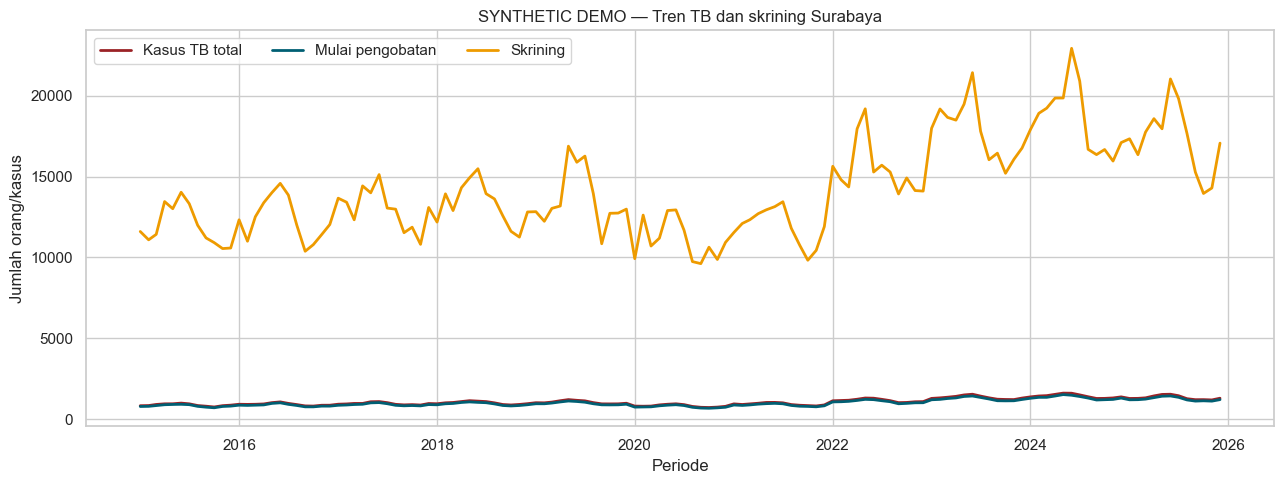

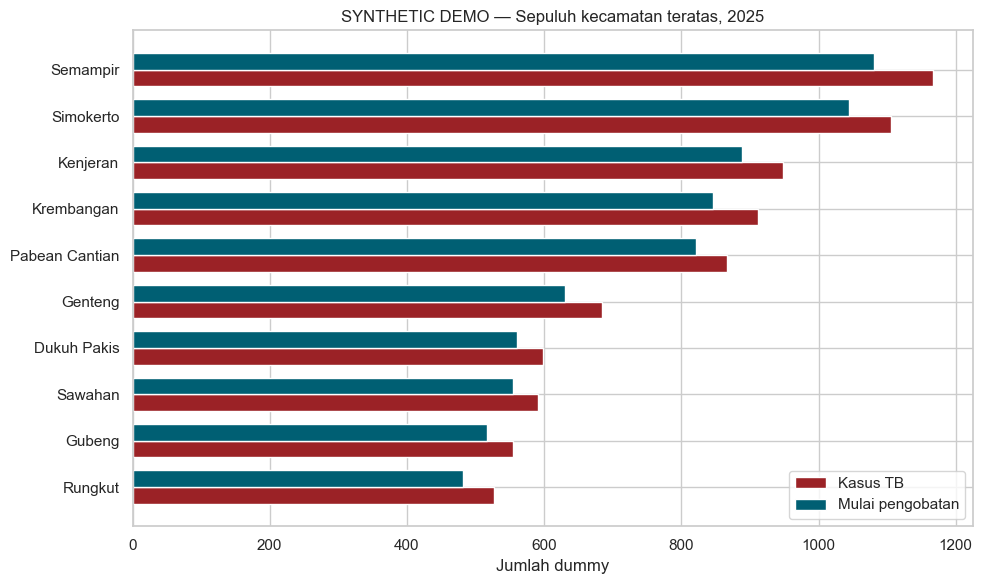

In [6]:
# 2.1 Tren kasus, pengobatan, dan skrining per bulan
tb = dummy["tb_monthly"].copy()
monthly = tb.groupby("period_dt", as_index=False).agg(
    kasus_tb=("kasus_tb_total_dummy", "sum"),
    mulai_pengobatan=("pasien_mulai_pengobatan_dummy", "sum"),
    skrining=("jumlah_skrining_dummy", "sum"),
)

fig, ax = plt.subplots(figsize=(13, 5))
for col, label, color in [
    ("kasus_tb", "Kasus TB total", "#9b2226"),
    ("mulai_pengobatan", "Mulai pengobatan", "#005f73"),
    ("skrining", "Skrining", "#ee9b00"),
]:
    ax.plot(monthly["period_dt"], monthly[col], label=label, linewidth=2, color=color)
ax.set_title("SYNTHETIC DEMO — Tren TB dan skrining Surabaya")
ax.set_xlabel("Periode")
ax.set_ylabel("Jumlah orang/kasus")
ax.legend(ncol=3)
finish_fig("dummy_trend_tb_screening.png")

# 2.2 Sepuluh kecamatan dengan kasus TB dummy tertinggi pada 2025
district_2025 = (
    tb[tb["tahun"] == 2025]
    .groupby("kecamatan", as_index=False)
    .agg(kasus_tb=("kasus_tb_total_dummy", "sum"), mulai_pengobatan=("pasien_mulai_pengobatan_dummy", "sum"))
    .nlargest(10, "kasus_tb")
    .sort_values("kasus_tb")
)
y = np.arange(len(district_2025))
h = 0.36
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(y - h / 2, district_2025["kasus_tb"], height=h, label="Kasus TB", color="#9b2226")
ax.barh(y + h / 2, district_2025["mulai_pengobatan"], height=h, label="Mulai pengobatan", color="#005f73")
ax.set_yticks(y, district_2025["kecamatan"])
ax.set_title("SYNTHETIC DEMO — Sepuluh kecamatan teratas, 2025")
ax.set_xlabel("Jumlah dummy")
ax.legend()
finish_fig("dummy_top_districts_2025.png")

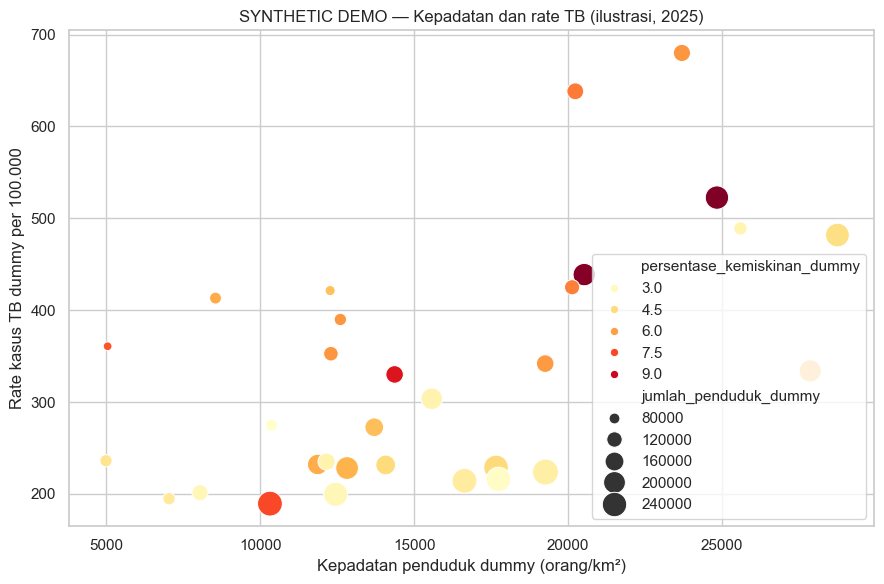

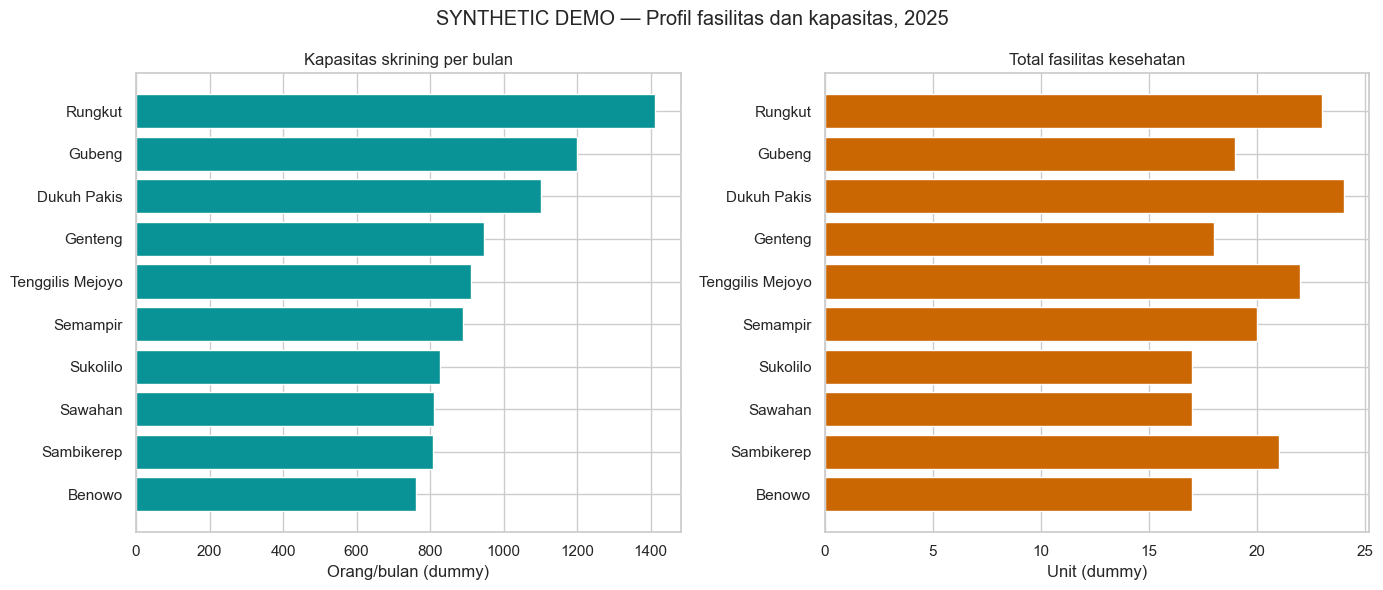

In [7]:
# 2.3 Hubungan ilustratif kepadatan penduduk dan rate kasus dummy
tb_2025 = tb[tb["tahun"] == 2025].groupby(["kecamatan_id", "kecamatan"], as_index=False).agg(
    kasus_tb=("kasus_tb_total_dummy", "sum")
)
social_2025 = social_d[social_d["tahun"] == 2025].copy()
social_join = tb_2025.merge(social_2025, on=["kecamatan_id", "kecamatan"], how="left")
social_join["rate_tb_dummy_per_100k"] = social_join["kasus_tb"] / social_join["jumlah_penduduk_dummy"] * 100000

fig, ax = plt.subplots(figsize=(9, 6))
if HAS_SEABORN:
    sns.scatterplot(
        data=social_join,
        x="kepadatan_penduduk_per_km2_dummy",
        y="rate_tb_dummy_per_100k",
        hue="persentase_kemiskinan_dummy",
        size="jumlah_penduduk_dummy",
        sizes=(40, 350),
        palette="YlOrRd",
        ax=ax,
    )
else:
    sc = ax.scatter(
        social_join["kepadatan_penduduk_per_km2_dummy"],
        social_join["rate_tb_dummy_per_100k"],
        c=social_join["persentase_kemiskinan_dummy"],
        s=np.sqrt(social_join["jumlah_penduduk_dummy"]) / 2,
        cmap="YlOrRd",
    )
    fig.colorbar(sc, ax=ax, label="Kemiskinan dummy (%)")
ax.set_title("SYNTHETIC DEMO — Kepadatan dan rate TB (ilustrasi, 2025)")
ax.set_xlabel("Kepadatan penduduk dummy (orang/km²)")
ax.set_ylabel("Rate kasus TB dummy per 100.000")
finish_fig("dummy_social_scatter.png")

# 2.4 Fasilitas dan kapasitas skrining
fac_plot = fac_d.copy()
fac_plot["total_faskes"] = fac_plot[["jumlah_puskesmas_dummy", "jumlah_pustu_dummy", "jumlah_klinik_dummy", "jumlah_rs_dummy"]].sum(axis=1)
fac_plot = fac_plot.nlargest(10, "kapasitas_skrining_per_bulan_dummy").sort_values("kapasitas_skrining_per_bulan_dummy")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(fac_plot["kecamatan"], fac_plot["kapasitas_skrining_per_bulan_dummy"], color="#0a9396")
axes[0].set_title("Kapasitas skrining per bulan")
axes[0].set_xlabel("Orang/bulan (dummy)")
axes[1].barh(fac_plot["kecamatan"], fac_plot["total_faskes"], color="#ca6702")
axes[1].set_title("Total fasilitas kesehatan")
axes[1].set_xlabel("Unit (dummy)")
fig.suptitle("SYNTHETIC DEMO — Profil fasilitas dan kapasitas, 2025")
finish_fig("dummy_facilities_capacity.png")

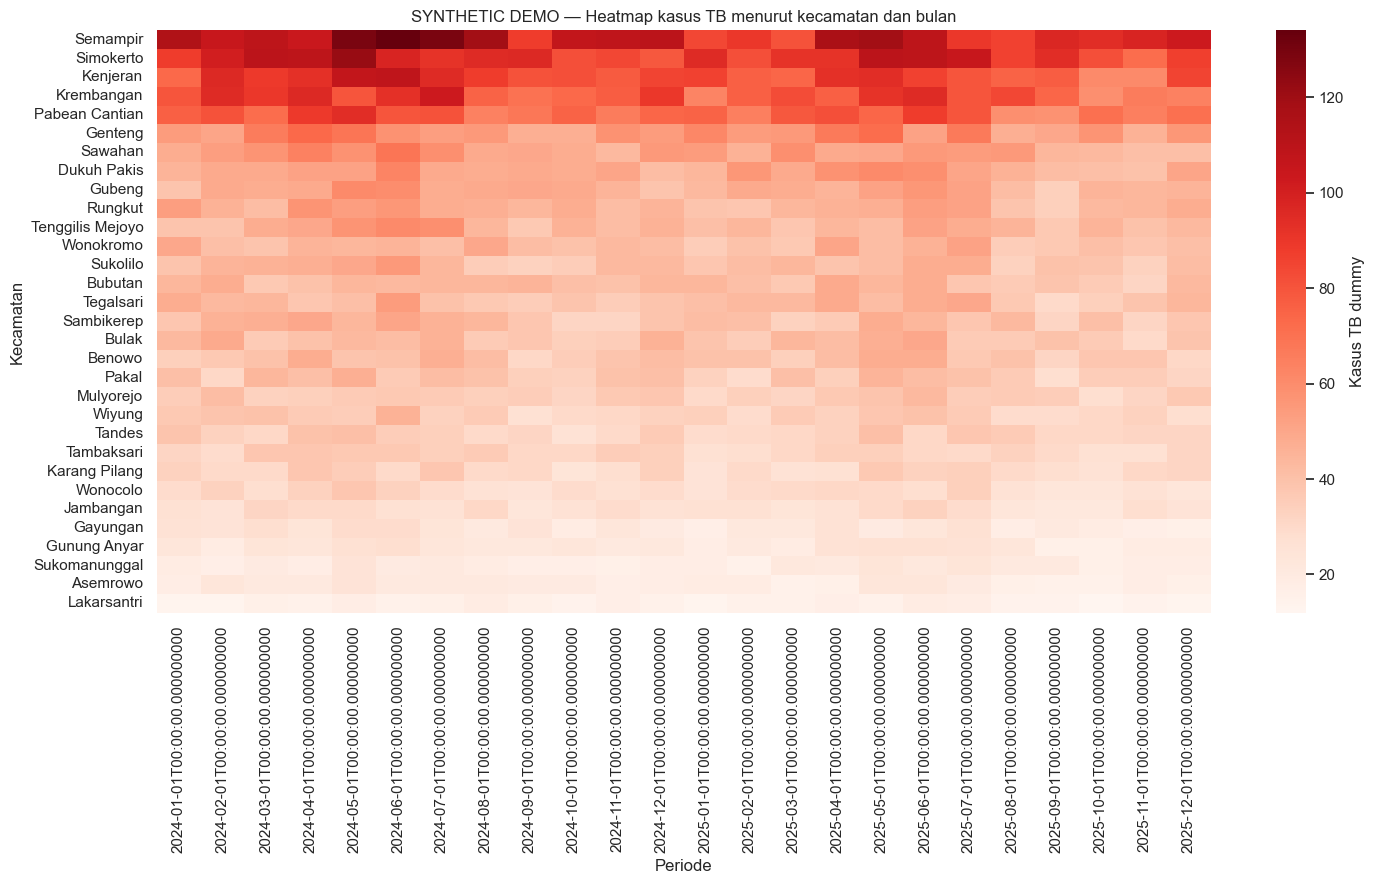

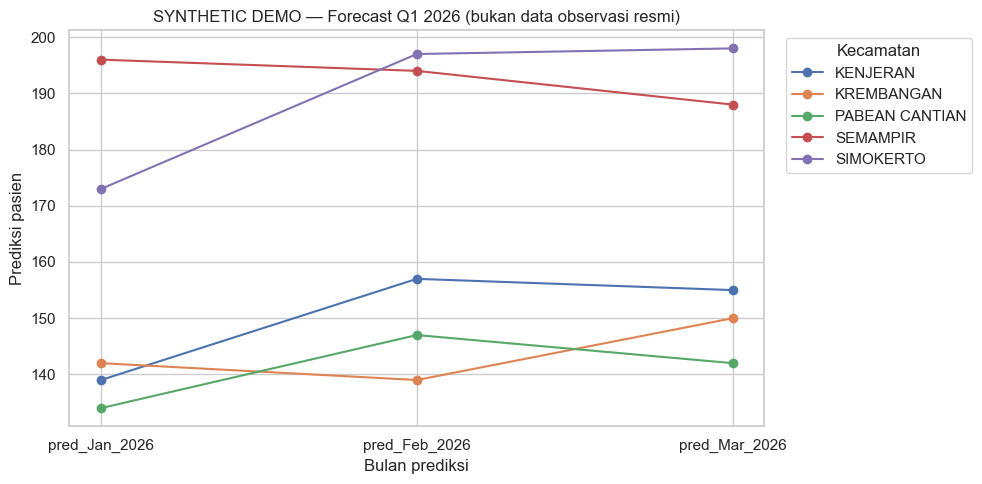

In [8]:
# 2.5 Heatmap kasus per kecamatan dan bulan (2024–2025)
heat = tb[tb["tahun"] >= 2024].pivot_table(
    index="kecamatan",
    columns="period_dt",
    values="kasus_tb_total_dummy",
    aggfunc="sum",
)
heat = heat.loc[heat.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(15, 9))
if HAS_SEABORN:
    sns.heatmap(heat, cmap="Reds", ax=ax, cbar_kws={"label": "Kasus TB dummy"})
else:
    im = ax.imshow(heat, aspect="auto", cmap="Reds")
    fig.colorbar(im, ax=ax, label="Kasus TB dummy")
ax.set_title("SYNTHETIC DEMO — Heatmap kasus TB menurut kecamatan dan bulan")
ax.set_xlabel("Periode")
ax.set_ylabel("Kecamatan")
finish_fig("dummy_heatmap_cases.png")

# 2.6 Forecast Q1 2026 untuk lima kecamatan dengan prediksi tertinggi
forecast = read_csv_rel("product-demo-synthetic/data/processed/forecast_results_2026.csv")
top_forecast = forecast.nlargest(5, "avg_pred_Q1")
forecast_long = top_forecast.melt(
    id_vars=["kecamatan"],
    value_vars=["pred_Jan_2026", "pred_Feb_2026", "pred_Mar_2026"],
    var_name="bulan_prediksi",
    value_name="prediksi",
)
fig, ax = plt.subplots(figsize=(10, 5))
for district, group in forecast_long.groupby("kecamatan"):
    ax.plot(group["bulan_prediksi"], group["prediksi"], marker="o", label=district)
ax.set_title("SYNTHETIC DEMO — Forecast Q1 2026 (bukan data observasi resmi)")
ax.set_xlabel("Bulan prediksi")
ax.set_ylabel("Prediksi pasien")
ax.legend(title="Kecamatan", bbox_to_anchor=(1.02, 1), loc="upper left")
finish_fig("dummy_forecast_q1_2026.png")

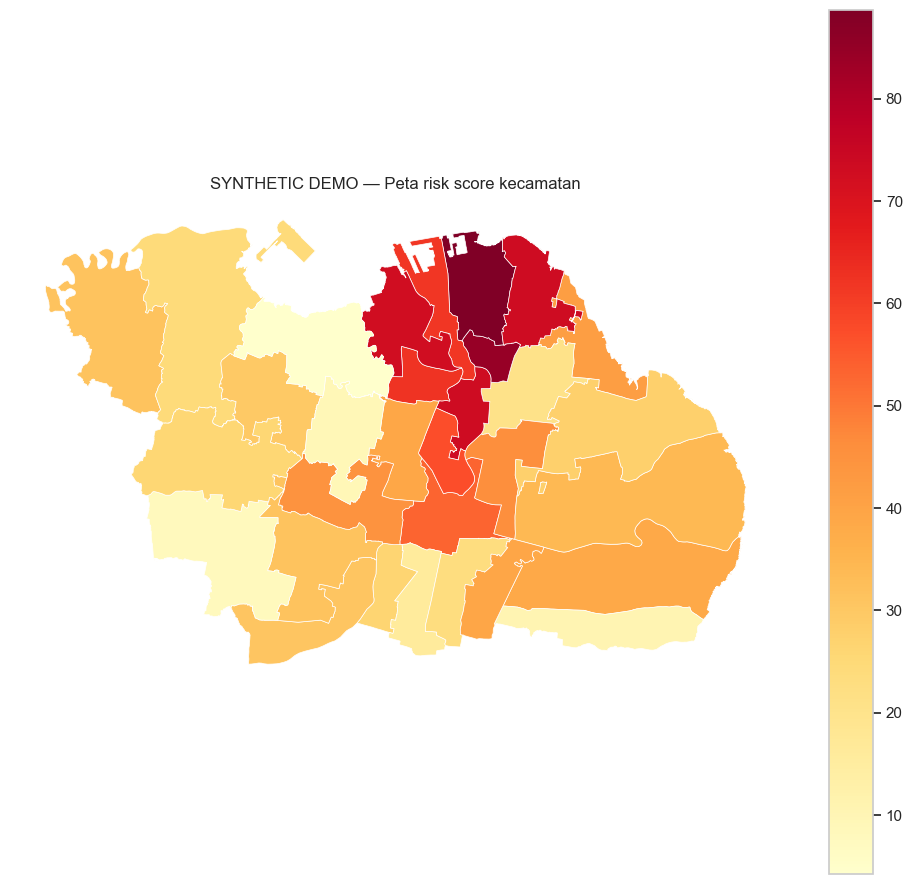

,kecamatan,risk_score,risk_zone,hotspot_zscore,hotspot_pvalue,kmeans_cluster,dbscan_anomaly
0,BULAK,41.518911,Medium Risk,0.458280,0.001,0,0
1,WONOKROMO,53.195331,Medium Risk,-0.193079,0.001,2,0
2,TAMBAKSARI,20.615041,Low Risk,0.413401,0.001,0,0
3,GENTENG,73.271240,High Risk,0.587751,0.001,2,0
4,BUBUTAN,62.511286,High Risk,0.708408,0.001,2,0
5,GUBENG,45.851220,Medium Risk,-0.110127,0.001,2,0
6,TEGALSARI,57.009008,Medium Risk,0.293967,0.001,2,0
7,SIMOKERTO,84.447765,High Risk,1.312800,0.001,2,0
8,JAMBANGAN,26.499514,Low Risk,-0.482588,0.001,0,0
9,GAYUNGAN,16.034044,Low Risk,-0.393778,0.001,0,0


In [9]:
# 2.7 Peta risiko kecamatan dari GeoJSON hasil olahan
risk_path = REPO_ROOT / "product-demo-synthetic/data/processed/master_dataset_spatial_risk_2024.geojson"
if HAS_GEOPANDAS and risk_path.exists():
    risk = gpd.read_file(risk_path)
    if "tahun" in risk.columns and (risk["tahun"] == 2024).any():
        risk = risk[risk["tahun"] == 2024].copy()
    fig, ax = plt.subplots(figsize=(10, 9))
    risk.plot(column="risk_score", cmap="YlOrRd", linewidth=0.5, edgecolor="white", legend=True, ax=ax)
    ax.set_title("SYNTHETIC DEMO — Peta risk score kecamatan")
    ax.set_axis_off()
    finish_fig("dummy_risk_map.png")
    display(risk[[c for c in ["kecamatan", "risk_score", "risk_zone", "hotspot_zscore", "hotspot_pvalue", "kmeans_cluster", "dbscan_anomaly"] if c in risk.columns]].head(10))
else:
    print("GeoPandas atau file GeoJSON tidak tersedia; peta dilewati.")

# 3. Dataset resmi/real

Dataset resmi memiliki unit analisis utama **provinsi–bulan** pada 2024–2025. Beberapa file lain memiliki tingkat waktu/geografi berbeda:

- tren nasional: nasional–bulan, 2023 sampai Juni 2026;
- profil tahunan: provinsi–tahun;
- BPS: provinsi–tahun atau reference-period;
- iklim dan bencana: provinsi–bulan;
- panel final: 38 provinsi × 24 bulan, 912 baris.

File di `raw/` dipertahankan sebagai sumber asli. File di `processed/` sudah diekstrak, dibersihkan, atau digabungkan untuk analisis.

In [10]:
real_paths = {
    "tb_national_month": "product-ongoing-real-data/data/processed/tb_national_month_official.csv",
    "tb_province_annual": "product-ongoing-real-data/data/processed/tb_province_annual_official.csv",
    "tb_outcomes_province_month": "product-ongoing-real-data/data/processed/tb_treatment_outcomes_province_month_official.csv",
    "tb_province_month_long": "product-ongoing-real-data/data/processed/tb_province_month_sitb_official.csv",
    "bps_annual": "product-ongoing-real-data/data/processed/bps_province_annual_official.csv",
    "climate_month": "product-ongoing-real-data/data/processed/climate_province_month_official.csv",
    "disaster_month": "product-ongoing-real-data/data/processed/bnpb_disaster_province_month_official.csv",
    "panel_final": "product-ongoing-real-data/data/processed/analysis_panel_tb_climate_disaster_2024_2025.csv",
    "codebook": "product-ongoing-real-data/data/processed/analysis_panel_tb_climate_codebook.csv",
    "source_ledger": "product-ongoing-real-data/data/processed/project_source_ledger.csv",
}

real = {name: read_csv_rel(path) for name, path in real_paths.items()}
real["tb_national_month"]["date_dt"] = pd.to_datetime(real["tb_national_month"]["date"])
real["tb_outcomes_province_month"]["period_dt"] = pd.to_datetime(real["tb_outcomes_province_month"]["period"] + "-01")
real["panel_final"]["period_dt"] = pd.to_datetime(real["panel_final"]["period"] + "-01")

for name, df in real.items():
    print(f"{name}: {df.shape[0]:,} baris x {df.shape[1]:,} kolom")

tb_national_month: 168 baris x 18 kolom
tb_province_annual: 38 baris x 24 kolom
tb_outcomes_province_month: 912 baris x 29 kolom
tb_province_month_long: 7,296 baris x 19 kolom
bps_annual: 152 baris x 18 kolom
climate_month: 912 baris x 39 kolom
disaster_month: 912 baris x 32 kolom
panel_final: 912 baris x 79 kolom
codebook: 78 baris x 4 kolom
source_ledger: 6 baris x 8 kolom


In [11]:
# Profil kolom setiap dataset resmi
for name, df in real.items():
    print(f"\n### {name}")
    display(profile_table(df))

print("\nCodebook panel final:")
display(real["codebook"])

print("\nSource ledger:")
display(real["source_ledger"])


### tb_national_month


,column,dtype,missing_n,missing_pct,unique_n
0,date_text,object,0,0.0,84
1,value,int64,0,0.0,168
2,date,object,0,0.0,42
3,indicator,object,0,0.0,4
4,requested_year,int64,0,0.0,4
5,source_file,object,0,0.0,16
6,year,int64,0,0.0,4
7,month,int64,0,0.0,12
8,period,object,0,0.0,42
9,is_complete_month,bool,0,0.0,1



### tb_province_annual


,column,dtype,missing_n,missing_pct,unique_n
0,province_code,int64,0,0.0,38
1,province,object,0,0.0,38
2,year,int64,0,0.0,1
3,estimated_tb_suspects,int64,0,0.0,38
4,tb_suspects_standard_service,int64,0,0.0,38
5,tb_suspects_standard_service_pct,int64,0,0.0,34
6,tb_cases_male,int64,0,0.0,38
7,tb_cases_male_pct,int64,0,0.0,12
8,tb_cases_female,int64,0,0.0,38
9,tb_cases_female_pct,int64,0,0.0,12



### tb_outcomes_province_month


...

,column,dtype,missing_n,missing_pct,unique_n
0,dataset_id,object,0,0.0,6
1,publisher,object,0,0.0,5
2,source_url,object,0,0.0,6
3,coverage,object,0,0.0,6
4,role,object,0,0.0,6
5,status,object,0,0.0,6
6,local_files,object,0,0.0,6
7,limitation,object,0,0.0,6



Codebook panel final:


,variable,definition,unit_or_type,source
0,province_code,BPS/Kemendagri-style province code used in the...,identifier,SITB/BPS harmonisation
1,province,Harmonised uppercase province name,identifier,SITB/BPS harmonisation
2,year,Calendar year of TB treatment-start cohort month,time,SITB
3,month,Calendar month 1-12,time,SITB
4,period,Year-month key YYYY-MM,time,Derived
5,jumlah_pasien,Patients starting drug-susceptible TB treatmen...,count,SITB
6,sembuh,Sembuh,see source,Source/derived
7,pengobatan_lengkap,Pengobatan lengkap,see source,Source/derived
8,lost_to_follow_up,Lost to follow up,see source,Source/derived
9,meninggal,Meninggal,see source,Source/derived



Source ledger:


,dataset_id,publisher,source_url,coverage,role,status,local_files,limitation
0,SITB_TREATMENT_OUTCOMES_PROVINCE_MONTH,Kementerian Kesehatan RI - SITB,https://tbdashboard.sitb.id/ss_data_tbc03so_20...,38 provinces; monthly; 2024-2025,Primary outcome,Complete for public 2024-2025 endpoints,data/raw/sitb_dashboard/*.csv; data/processed/...,"Treatment-start cohorts, not TB incidence. 202..."
1,BPS_PROVINCE_ANNUAL_COVARIATES,Badan Pusat Statistik,https://www.bps.go.id/,38 provinces; annual; 2023-2026 depending on i...,Population offset and structural covariates,"Complete for population, density, sanitation, ...",data/raw/bps/*.pdf; data/processed/bps_provinc...,Annual/survey-period measures repeated across ...
2,NASA_POWER_MERRA2_MONTHLY,NASA POWER,https://power.larc.nasa.gov/docs/services/api/...,38 provinces; monthly 1981-2025; panel output ...,"Primary exposures: temperature, humidity, prec...","Complete, 912/912 panel rows",data/raw/nasa_power/*.nc; data/processed/clima...,"Reanalysis grid, not station observations; sma..."
3,BIG_PROVINCE_BOUNDARIES,Badan Informasi Geospasial,https://geoservices.big.go.id/rbi/rest/service...,38 provinces; official polygon service snapshot,Spatial aggregation support,Complete; generalized export processed,data/raw/big/big_province_boundaries_generaliz...,Generalized to 0.05 degrees and topology-repai...
4,BNPB_OPERATIONAL_EVENTS,Badan Nasional Penanggulangan Bencana,https://gis.bnpb.go.id/databencana/tabel/penca...,Dated event records; 2024-2025; 38 provinces a...,Secondary/sensitivity covariate,"Extracted; 7,143 deduplicated records and 912 ...",data/raw/bnpb/bnpb_event_search_2024_2025_raw....,Operational snapshot does not fully reconcile ...
5,BNPB_ANNUAL_BENCHMARKS,Badan Nasional Penanggulangan Bencana,https://data.bnpb.go.id/dataset/data-bencana-i...,38 provinces; annual 2024-2025,Quality benchmark for operational event panel,Complete and reconciled by province name,data/raw/bnpb/jumlah_kejadian_bencana_menurut_...,Annual only; formal threshold/compilation diff...


In [12]:
# Ringkasan file validasi JSON yang ada di processed/
validation_files = sorted((REAL_ROOT / "data" / "processed").glob("*validation.json"))

def flatten_dict(obj, prefix=""):
    result = {}
    if isinstance(obj, dict):
        for key, value in obj.items():
            result.update(flatten_dict(value, f"{prefix}.{key}" if prefix else key))
    else:
        result[prefix] = obj
    return result

validation_rows = []
for path in validation_files:
    payload = json.loads(path.read_text(encoding="utf-8"))
    flat = flatten_dict(payload)
    compact = "; ".join(f"{key}={value}" for key, value in list(flat.items())[:12])
    validation_rows.append({"file": path.name, "summary": compact})
display(pd.DataFrame(validation_rows))

,file,summary
0,analysis_panel_tb_climate_validation.json,rows=912; provinces=38; periods=24; duplicate_...
1,bnpb_disaster_province_month_validation.json,raw_rows=7164; exact_duplicate_substantive_row...
2,bps_province_validation.json,"rows=152; provinces=38; years=[2023, 2024, 202..."
3,climate_province_month_validation.json,rows=912; provinces=38; periods=24; duplicate_...
4,tb_national_month_validation.json,raw_files=16; successful_files=16; failed_file...
5,tb_province_annual_validation.json,rows=38; provinces=38; year=2024; tb_cases_tot...
6,tb_province_month_validation.json,source=Kementerian Kesehatan RI SITB public TB...


## Fungsi setiap dataset resmi

### Data TB

- **`tb_national_month_official.csv`**: empat indikator nasional (`notified`, `suspected`, `tested`, `treated`) untuk grafik tren nasional.
- **`tb_province_annual_official.csv`**: total kasus, rate notifikasi, estimasi insidensi, cakupan layanan, jenis kelamin, dan kasus anak untuk profil tahunan provinsi.
- **`tb_treatment_outcomes_province_month_official.csv`**: cohort pasien yang mulai pengobatan dan hasil akhirnya. Ini adalah sumber utama outcome penelitian.
- **`tb_province_month_sitb_official.csv`**: bentuk long-format dari data provinsi-bulanan untuk grafik multi-indikator.

### Data sosial

- **`bps_province_annual_official.csv`**: populasi, kepadatan, sanitasi, dan kemiskinan. Populasi digunakan sebagai denominator rate; sanitasi dan kemiskinan menjadi variabel konteks.

### Data cuaca/iklim

- **`climate_province_month_official.csv`**: suhu, kelembapan, curah hujan, normal 1991–2020, anomaly, z-score, lag satu-dua bulan, rata-rata lag 0–2 bulan, serta flag `heavy_rain_anomaly` dan `hot_anomaly`.

### Data bencana dan geospasial

- **`bnpb_disaster_province_month_official.csv`**: jumlah kejadian dan dampak bencana per provinsi-bulan. Dataset ini adalah covariate sekunder/sensitivity.
- **`big_province_boundaries_generalized.geojson`**: geometri provinsi untuk peta dan spatial join; bukan batas legal.

### Metadata

- **`analysis_panel_tb_climate_codebook.csv`**: definisi variabel panel final.
- **`project_source_ledger.csv`**: sumber, URL, cakupan, peran, status, dan keterbatasan.
- **`*_validation.json`**: hasil pemeriksaan jumlah baris, duplikasi, kelengkapan, dan keseimbangan outcome.

File WHO, PDF BPS/Kemenkes, XLSX BNPB, HTML BNPB, dan NetCDF NASA POWER di folder `raw/` adalah arsip sumber mentah. File-file tersebut tidak seharusnya diedit langsung.

In [13]:
# QA dasar panel resmi
panel = real["panel_final"]
outcomes = real["tb_outcomes_province_month"]
national = real["tb_national_month"]
climate = real["climate_month"]
disaster = real["disaster_month"]

real_checks = [
    {"check": "Panel memiliki 38 provinsi", "value": panel["province_code"].nunique(), "pass": panel["province_code"].nunique() == 38},
    {"check": "Panel memiliki 24 periode", "value": panel["period"].nunique(), "pass": panel["period"].nunique() == 24},
    {"check": "Panel tidak duplikat province-period", "value": int(panel.duplicated(["province_code", "period"]).sum()), "pass": not panel.duplicated(["province_code", "period"]).any()},
    {"check": "Outcome sum sama dengan jumlah pasien", "value": int((outcomes["outcome_sum"] != outcomes["jumlah_pasien"]).sum()), "pass": (outcomes["outcome_sum"] == outcomes["jumlah_pasien"]).all()},
    {"check": "Panel climate lengkap", "value": len(climate), "pass": len(climate) == len(panel)},
    {"check": "Panel disaster lengkap", "value": len(disaster), "pass": len(disaster) == len(panel)},
    {"check": "National memiliki 4 indikator", "value": national["indicator"].nunique(), "pass": national["indicator"].nunique() == 4},
]
display(pd.DataFrame(real_checks))

maturity_summary = (
    panel.groupby("year", as_index=False)
    .agg(
        cohort_count=("province_code", "size"),
        avg_pending_share=("pending_share", "mean"),
        mature_cohort_count=("cohort_maturity_flag", lambda s: (s == "mature_le_5pct_pending").sum()),
    )
)
maturity_summary["avg_pending_pct"] = maturity_summary["avg_pending_share"] * 100
display(maturity_summary)

,check,value,pass
0,Panel memiliki 38 provinsi,38,True
1,Panel memiliki 24 periode,24,True
2,Panel tidak duplikat province-period,0,True
3,Outcome sum sama dengan jumlah pasien,0,True
4,Panel climate lengkap,912,True
5,Panel disaster lengkap,912,True
6,National memiliki 4 indikator,4,True


,year,cohort_count,avg_pending_share,mature_cohort_count,avg_pending_pct
0,2024,456,0.028015,375,2.801501
1,2025,456,0.153898,80,15.389766


## Variabel inti data real untuk dashboard

- **Outcome utama:** `jumlah_pasien` — pasien yang mulai pengobatan TB sensitif obat pada bulan pelaporan.
- **Outcome diketahui:** `known_outcome_count` dan `pending_share`.
- **Keberhasilan:** `treatment_success_all_share` menggunakan seluruh cohort sebagai penyebut; `treatment_success_known_share` hanya menggunakan outcome yang sudah diketahui.
- **Kematangan cohort:** `cohort_maturity_flag` bernilai matang ketika `pending_share <= 5%`.
- **Rate:** `treatment_started_per_100k` menggunakan populasi tahunan BPS sebagai denominator.
- **Iklim:** variabel dasar, anomaly, z-score, dan lag.
- **Bencana:** jumlah kejadian dan dampak yang tersedia pada tabel operasional BNPB.

Variabel `source_url`, `snapshot_retrieved_at`, `quality_flag`, `disaster_quality_flag`, dan `climate_spatial_method` sebaiknya ikut dibawa ke tooltip atau source drawer.

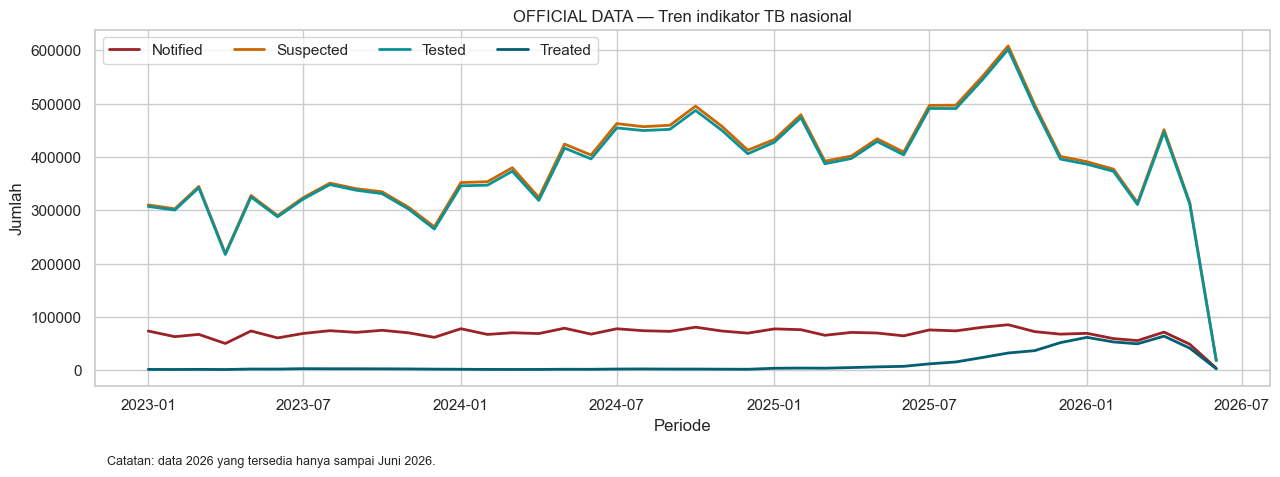

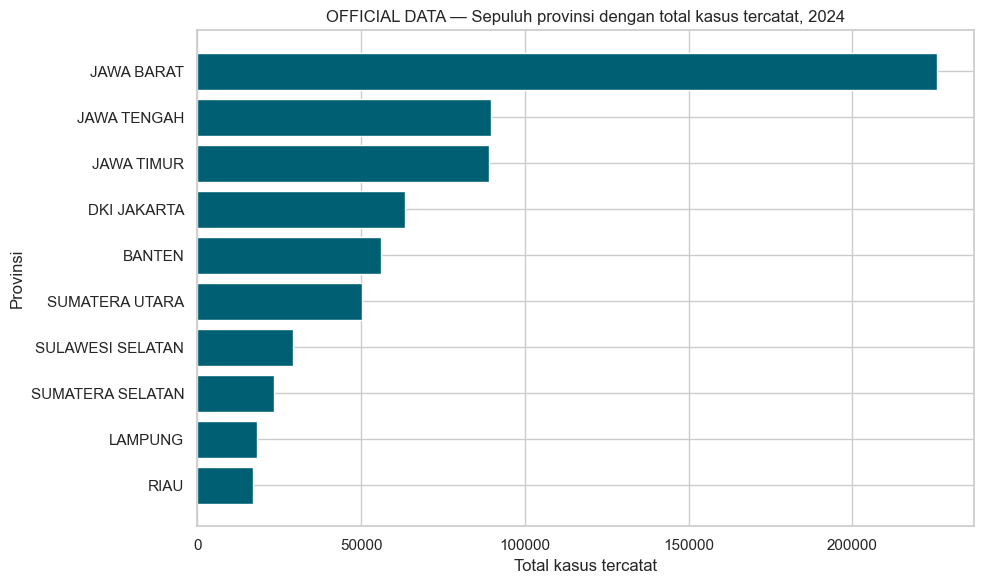

In [14]:
# 3.1 Tren nasional: notified, suspected, tested, treated
nat_pivot = national.pivot_table(index="date_dt", columns="indicator", values="value", aggfunc="sum").sort_index()
fig, ax = plt.subplots(figsize=(13, 5))
colors = {"notified": "#9b2226", "suspected": "#ca6702", "tested": "#0a9396", "treated": "#005f73"}
for col in ["notified", "suspected", "tested", "treated"]:
    if col in nat_pivot.columns:
        ax.plot(nat_pivot.index, nat_pivot[col], label=col.title(), color=colors.get(col), linewidth=2)
ax.set_title("OFFICIAL DATA — Tren indikator TB nasional")
ax.set_xlabel("Periode")
ax.set_ylabel("Jumlah")
ax.legend(ncol=4)
ax.text(0.01, -0.22, "Catatan: data 2026 yang tersedia hanya sampai Juni 2026.", transform=ax.transAxes, fontsize=9)
finish_fig("real_national_tb_trend.png")

# 3.2 Ranking provinsi berdasarkan kasus tahunan 2024
annual = real["tb_province_annual"].copy()
top_annual = annual.nlargest(10, "tb_cases_total").sort_values("tb_cases_total")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_annual["province"], top_annual["tb_cases_total"], color="#005f73")
ax.set_title("OFFICIAL DATA — Sepuluh provinsi dengan total kasus tercatat, 2024")
ax.set_xlabel("Total kasus tercatat")
ax.set_ylabel("Provinsi")
finish_fig("real_top_provinces_annual.png")

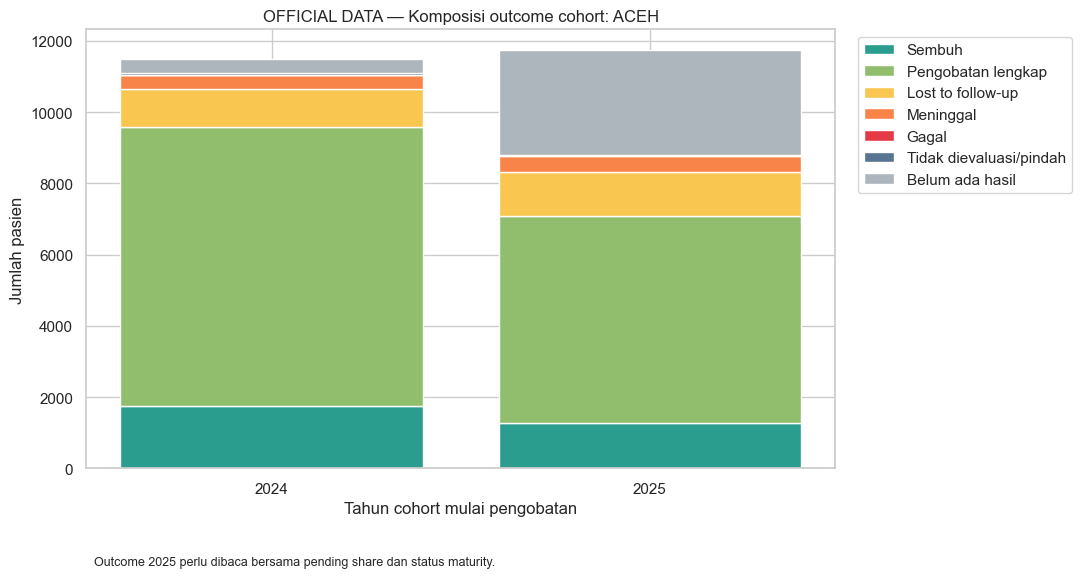

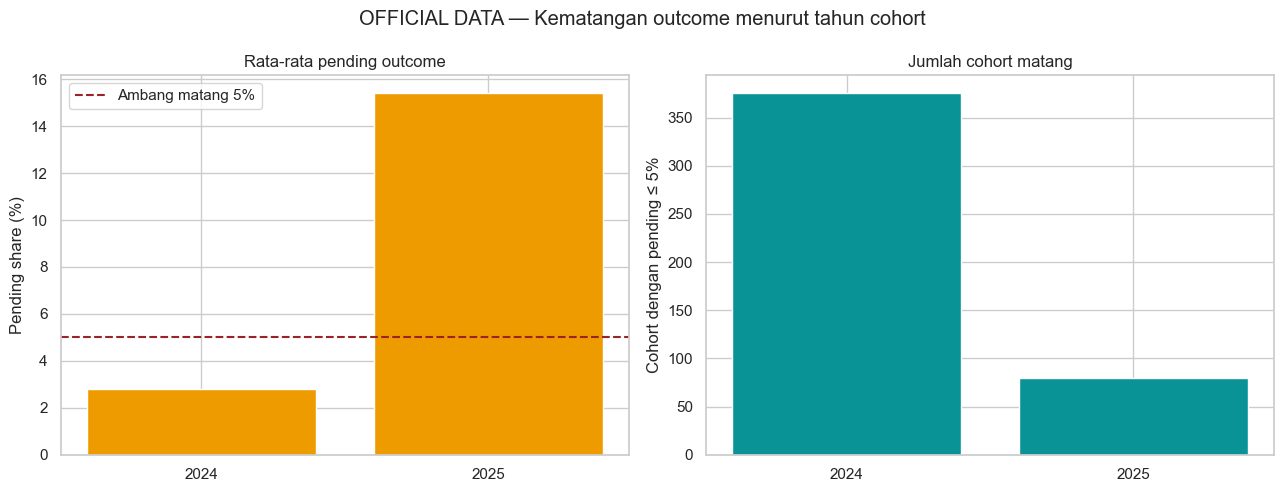

In [15]:
# 3.3 Komposisi outcome untuk provinsi contoh
outcome_cols = ["sembuh", "pengobatan_lengkap", "lost_to_follow_up", "meninggal", "gagal", "tidak_dievaluasi_pindah", "belum_ada_hasil"]
outcome_labels = {
    "sembuh": "Sembuh",
    "pengobatan_lengkap": "Pengobatan lengkap",
    "lost_to_follow_up": "Lost to follow-up",
    "meninggal": "Meninggal",
    "gagal": "Gagal",
    "tidak_dievaluasi_pindah": "Tidak dievaluasi/pindah",
    "belum_ada_hasil": "Belum ada hasil",
}
selected_province = "ACEH" if "ACEH" in outcomes["province"].unique() else outcomes["province"].iloc[0]
selected_outcome = outcomes[outcomes["province"] == selected_province]
composition = selected_outcome.groupby("year")[outcome_cols].sum()
fig, ax = plt.subplots(figsize=(11, 6))
bottom = np.zeros(len(composition))
palette = ["#2a9d8f", "#90be6d", "#f9c74f", "#f9844a", "#e63946", "#577590", "#adb5bd"]
for col, color in zip(outcome_cols, palette):
    values = composition[col].to_numpy()
    ax.bar(composition.index.astype(str), values, bottom=bottom, label=outcome_labels[col], color=color)
    bottom += values
ax.set_title(f"OFFICIAL DATA — Komposisi outcome cohort: {selected_province}")
ax.set_xlabel("Tahun cohort mulai pengobatan")
ax.set_ylabel("Jumlah pasien")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.text(0.01, -0.22, "Outcome 2025 perlu dibaca bersama pending share dan status maturity.", transform=ax.transAxes, fontsize=9)
finish_fig("real_outcome_composition.png")

# 3.4 Status provisional dan kematangan cohort
maturity = panel.groupby("year", as_index=False).agg(
    avg_pending=("pending_share", "mean"),
    mature_count=("cohort_maturity_flag", lambda s: (s == "mature_le_5pct_pending").sum()),
    cohort_count=("province_code", "size"),
)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(maturity["year"].astype(str), maturity["avg_pending"] * 100, color="#ee9b00")
axes[0].axhline(5, color="#9b2226", linestyle="--", label="Ambang matang 5%")
axes[0].set_title("Rata-rata pending outcome")
axes[0].set_ylabel("Pending share (%)")
axes[0].legend()
axes[1].bar(maturity["year"].astype(str), maturity["mature_count"], color="#0a9396")
axes[1].set_title("Jumlah cohort matang")
axes[1].set_ylabel("Cohort dengan pending ≤ 5%")
fig.suptitle("OFFICIAL DATA — Kematangan outcome menurut tahun cohort")
finish_fig("real_maturity_provisional.png")

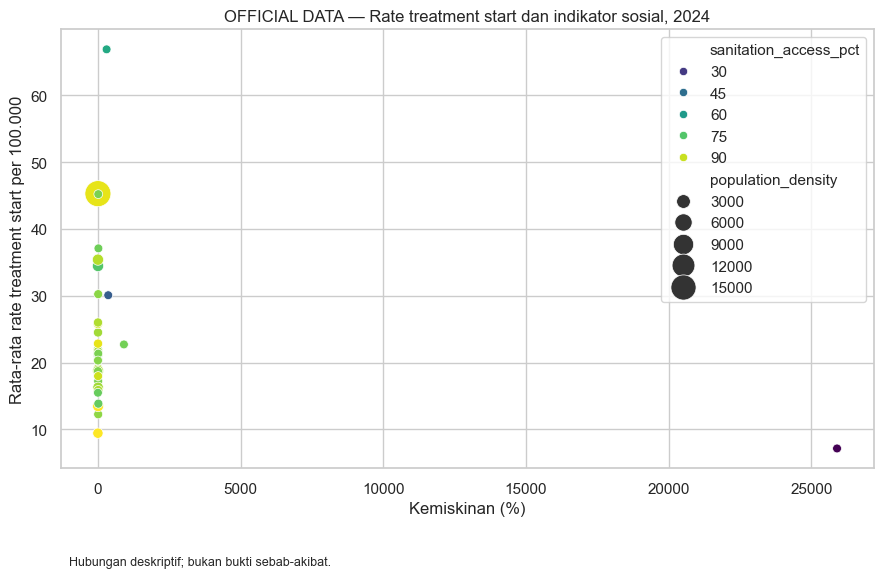

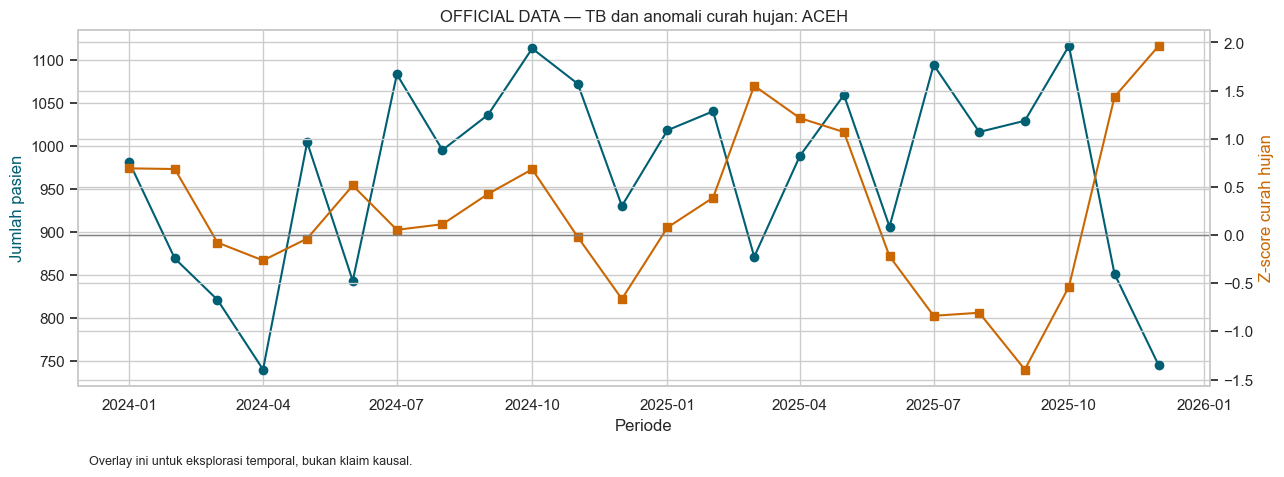

In [16]:
# 3.5 Hubungan deskriptif variabel sosial dengan rate treatment start
panel_2024 = panel[panel["year"] == 2024].copy()
social_province = panel_2024.groupby(["province_code", "province"], as_index=False).agg(
    mean_rate=("treatment_started_per_100k", "mean"),
    population_density=("population_density_per_km2", "first"),
    poverty_pct=("poverty_pct", "first"),
    sanitation_access_pct=("sanitation_access_pct", "first"),
)
social_province = social_province.dropna(subset=["mean_rate", "poverty_pct"])
fig, ax = plt.subplots(figsize=(9, 6))
if HAS_SEABORN:
    sns.scatterplot(
        data=social_province,
        x="poverty_pct",
        y="mean_rate",
        hue="sanitation_access_pct",
        size="population_density",
        sizes=(40, 350),
        palette="viridis",
        ax=ax,
    )
else:
    sc = ax.scatter(social_province["poverty_pct"], social_province["mean_rate"], c=social_province["sanitation_access_pct"], cmap="viridis")
    fig.colorbar(sc, ax=ax, label="Akses sanitasi (%)")
ax.set_title("OFFICIAL DATA — Rate treatment start dan indikator sosial, 2024")
ax.set_xlabel("Kemiskinan (%)")
ax.set_ylabel("Rata-rata rate treatment start per 100.000")
ax.text(0.01, -0.22, "Hubungan deskriptif; bukan bukti sebab-akibat.", transform=ax.transAxes, fontsize=9)
finish_fig("real_social_rate_scatter.png")

# 3.6 Contoh overlay treatment start dan anomali curah hujan
selected_panel = panel[panel["province"] == selected_province].sort_values("period_dt")
fig, ax1 = plt.subplots(figsize=(13, 5))
ax1.plot(selected_panel["period_dt"], selected_panel["jumlah_pasien"], color="#005f73", marker="o", label="Jumlah pasien mulai pengobatan")
ax1.set_xlabel("Periode")
ax1.set_ylabel("Jumlah pasien", color="#005f73")
ax2 = ax1.twinx()
ax2.plot(selected_panel["period_dt"], selected_panel["precipitation_mm_z_mean_lag0_2"], color="#ca6702", marker="s", label="Z curah hujan rata-rata lag 0–2")
ax2.axhline(0, color="gray", linewidth=1)
ax2.set_ylabel("Z-score curah hujan", color="#ca6702")
ax1.set_title(f"OFFICIAL DATA — TB dan anomali curah hujan: {selected_province}")
ax1.text(0.01, -0.22, "Overlay ini untuk eksplorasi temporal, bukan klaim kausal.", transform=ax1.transAxes, fontsize=9)
finish_fig("real_tb_climate_overlay.png")

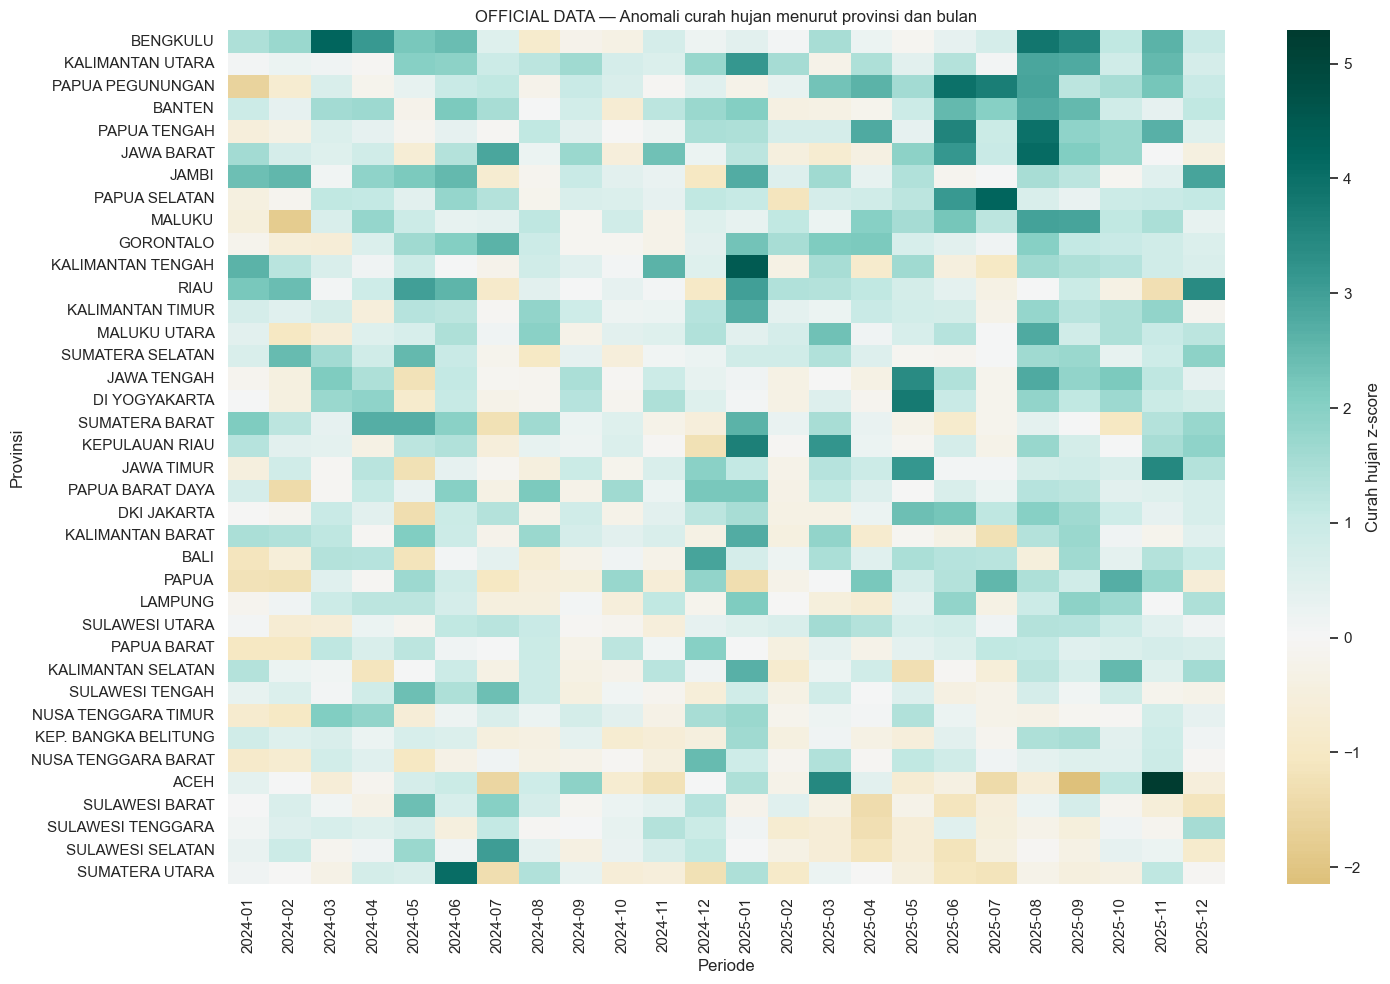

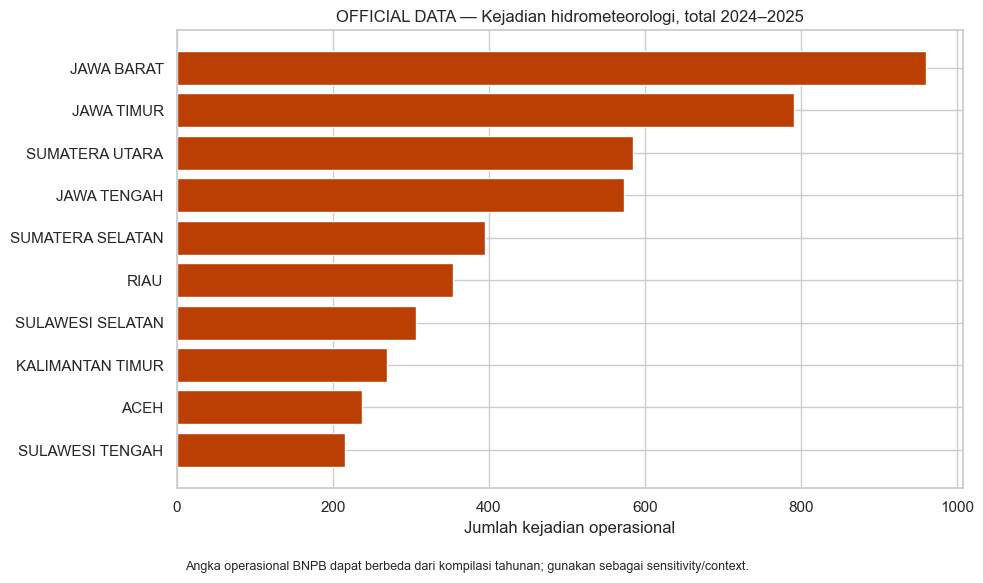

In [17]:
# 3.7 Heatmap anomali curah hujan antarprovinsi
climate_heat = climate.pivot_table(index="province", columns="period", values="precipitation_mm_z", aggfunc="mean")
climate_heat = climate_heat.loc[climate_heat.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(15, 10))
if HAS_SEABORN:
    sns.heatmap(climate_heat, cmap="BrBG", center=0, ax=ax, cbar_kws={"label": "Curah hujan z-score"})
else:
    im = ax.imshow(climate_heat, aspect="auto", cmap="BrBG", vmin=-2, vmax=2)
    fig.colorbar(im, ax=ax, label="Curah hujan z-score")
ax.set_title("OFFICIAL DATA — Anomali curah hujan menurut provinsi dan bulan")
ax.set_xlabel("Periode")
ax.set_ylabel("Provinsi")
finish_fig("real_precipitation_heatmap.png")

# 3.8 Provinsi dengan kejadian hidrometeorologi terbanyak
disaster_top = (
    disaster.groupby("province", as_index=False)["hydrometeorological_events"]
    .sum()
    .nlargest(10, "hydrometeorological_events")
    .sort_values("hydrometeorological_events")
)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(disaster_top["province"], disaster_top["hydrometeorological_events"], color="#bb3e03")
ax.set_title("OFFICIAL DATA — Kejadian hidrometeorologi, total 2024–2025")
ax.set_xlabel("Jumlah kejadian operasional")
ax.text(0.01, -0.18, "Angka operasional BNPB dapat berbeda dari kompilasi tahunan; gunakan sebagai sensitivity/context.", transform=ax.transAxes, fontsize=9)
finish_fig("real_disaster_hydromet_ranking.png")

In [18]:
# 3.9 Peta provinsi berdasarkan case notification rate 2024
boundary_path = REAL_ROOT / "data" / "raw" / "big" / "big_province_boundaries_generalized.geojson"
if HAS_GEOPANDAS and boundary_path.exists():
    boundaries = gpd.read_file(boundary_path)
    # BIG menyimpan satu provinsi sebagai beberapa polygon. Gabungkan berdasarkan kode provinsi.
    boundaries["province_code"] = pd.to_numeric(boundaries["kdppum"], errors="coerce").astype("Int64").astype(str).str.zfill(2)
    boundaries = boundaries.dropna(subset=["province_code"])
    boundaries = boundaries.dissolve(by="province_code", as_index=False)
    annual_map = annual.copy()
    annual_map["province_code"] = pd.to_numeric(annual_map["province_code"], errors="coerce").astype("Int64").astype(str).str.zfill(2)
    map_join = boundaries.merge(annual_map[["province_code", "province", "case_notification_rate_per_100k"]], on="province_code", how="left")
    fig, ax = plt.subplots(figsize=(11, 10))
    map_join.plot(column="case_notification_rate_per_100k", cmap="YlOrRd", linewidth=0.3, edgecolor="white", legend=True, ax=ax, missing_kwds={"color": "lightgrey", "label": "Tidak ada pasangan data"})
    ax.set_title("OFFICIAL DATA — Case notification rate per 100.000, 2024")
    ax.set_axis_off()
    finish_fig("real_province_rate_map.png")
    print("Provinsi tanpa pasangan geometri/data:", int(map_join["case_notification_rate_per_100k"].isna().sum()))
else:
    print("GeoPandas atau batas BIG tidak tersedia; peta dilewati.")

GEOSException: TopologyException: unable to assign free hole to a shell at 96.487899999999996 2.4005000000000001 0

In [ ]:
# 3.10 Korelasi eksploratori pada panel final
corr_vars = [
    "treatment_started_per_100k",
    "poverty_pct",
    "sanitation_access_pct",
    "temperature_c_z",
    "relative_humidity_pct_z",
    "precipitation_mm_z",
    "hydrometeorological_events",
]
corr_vars = [c for c in corr_vars if c in panel.columns]
corr = panel[corr_vars].corr()
fig, ax = plt.subplots(figsize=(9, 7))
if HAS_SEABORN:
    sns.heatmap(corr, annot=True, fmt=".2f", center=0, cmap="vlag", ax=ax)
else:
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
    fig.colorbar(im, ax=ax)
    ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(corr.index)), corr.index)
ax.set_title("OFFICIAL DATA — Korelasi eksploratori panel final")
finish_fig("real_panel_correlation_heatmap.png")
print("Interpretasi korelasi tidak boleh ditulis sebagai hubungan sebab-akibat.")

# 4. Katalog visualisasi untuk rancangan dashboard

Tabel berikut dapat dipakai sebagai jembatan dari dataset ke information architecture. Kolom `display_rule` dapat langsung dikembangkan menjadi spesifikasi UI atau data contract backend.

In [ ]:
dashboard_reference = pd.DataFrame([
    {
        "lane": "Synthetic Demo",
        "page": "Overview",
        "research_question": "Apa situasi demo di Surabaya?",
        "dataset": "TB monthly + social annual + facilities",
        "variables": "kasus_tb_total_dummy; pasien_mulai_pengobatan_dummy; jumlah_skrining_dummy; risk_zone",
        "visual_reference": "KPI cards + summary bar + status alert",
        "display_rule": "Badge SYNTHETIC DEMO selalu terlihat",
    },
    {
        "lane": "Synthetic Demo",
        "page": "Trend",
        "research_question": "Bagaimana perubahan menurut bulan?",
        "dataset": "TB monthly",
        "variables": "kasus_tb_total_dummy; positivity_rate_dummy; pasien_dropout_dummy",
        "visual_reference": "Multi-line chart + district filter",
        "display_rule": "Forecast digambar putus-putus dan diberi label simulasi",
    },
    {
        "lane": "Synthetic Demo",
        "page": "Map",
        "research_question": "Kecamatan mana yang memiliki skor risiko tinggi?",
        "dataset": "master_dataset_spatial_risk_2024.geojson",
        "variables": "risk_score; risk_zone; hotspot_zscore; kmeans_cluster; dbscan_anomaly",
        "visual_reference": "Choropleth + click-to-detail + allocation drawer",
        "display_rule": "Tidak digunakan untuk kesimpulan epidemiologi",
    },
    {
        "lane": "Official Research",
        "page": "Overview",
        "research_question": "Berapa pasien yang memulai pengobatan dan seberapa lengkap datanya?",
        "dataset": "panel_final",
        "variables": "jumlah_pasien; treatment_started_per_100k; pending_share; cohort_maturity_flag",
        "visual_reference": "KPI + data maturity banner",
        "display_rule": "Tampilkan status 2025 provisional dan snapshot date",
    },
    {
        "lane": "Official Research",
        "page": "Trend",
        "research_question": "Kapan perubahan TB, iklim, atau bencana terlihat?",
        "dataset": "national month + panel final",
        "variables": "notified; suspected; tested; treated; temperature_c_z; precipitation_mm_z",
        "visual_reference": "Line chart + optional climate/disaster annotation",
        "display_rule": "2026 hanya YTD sampai Juni; overlay bukan klaim kausal",
    },
    {
        "lane": "Official Research",
        "page": "Map",
        "research_question": "Di provinsi mana terdapat perbedaan rate atau maturity?",
        "dataset": "province annual + panel final + BIG geometry",
        "variables": "case_notification_rate_per_100k; treatment_started_per_100k; pending_share",
        "visual_reference": "Province choropleth + layer toggle + profile drawer",
        "display_rule": "Batas BIG generalized; BNPB sebagai sensitivity/context",
    },
    {
        "lane": "Official Research",
        "page": "Methods",
        "research_question": "Bagaimana angka dan status dihitung?",
        "dataset": "codebook + validation files",
        "variables": "definition; unit; formula; cohort_maturity_flag; quality_flag",
        "visual_reference": "Metric glossary + formula cards + QA summary",
        "display_rule": "Gunakan istilah asosiasi eksploratori, bukan sebab-akibat",
    },
    {
        "lane": "Official Research",
        "page": "Sources",
        "research_question": "Dari mana angka berasal dan apa batasannya?",
        "dataset": "project_source_ledger + row-level metadata",
        "variables": "source_url; source_publisher; snapshot_retrieved_at; quality_flag",
        "visual_reference": "Source ledger table + provenance drawer",
        "display_rule": "Tampilkan sumber dan reference period dalam satu klik",
    },
])
display(dashboard_reference)

# 5. Checklist sebelum notebook atau dashboard dipakai

1. Pastikan mode **Synthetic Demo** dan **Official Research** memiliki branding/status yang berbeda.
2. Setiap angka memiliki definisi, unit, periode, wilayah, dan sumber.
3. Bedakan jumlah, rate, persentase, indeks, dan output model.
4. Tampilkan `pending_share` dan `cohort_maturity_flag` ketika membahas outcome 2025.
5. Tandai 2026 sebagai data parsial sampai Juni 2026.
6. Jelaskan bahwa BPS tahunan diulang sebagai reference value, bukan pengamatan bulanan.
7. Tandai iklim sebagai reanalysis dan BNPB sebagai data operasional/sensitivity.
8. Jangan menggambarkan hubungan eksploratori sebagai sebab-akibat.
9. Jangan mengubah file `raw/` langsung; simpan transformasi pada pipeline atau file `processed/` baru.
10. Sebelum mengunci copy Methods, selaraskan versi dataset dan formula risk score yang digunakan oleh tim.

Notebook ini menghasilkan referensi eksplorasi. Untuk dashboard produksi, nilai dan transformasi final tetap perlu disepakati dengan pemilik data atau peneliti.